# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

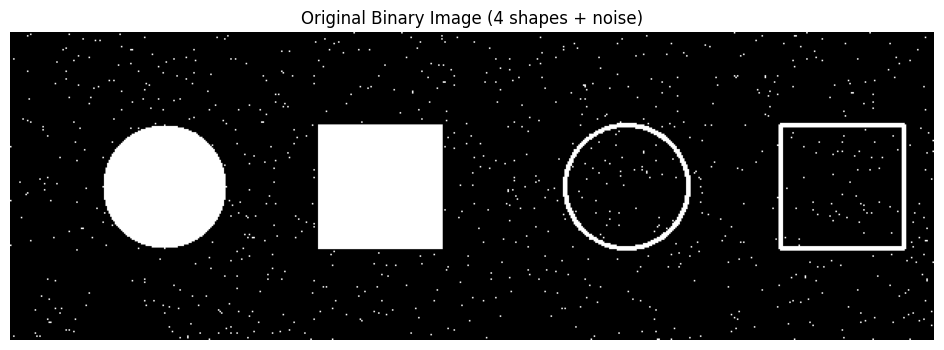

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



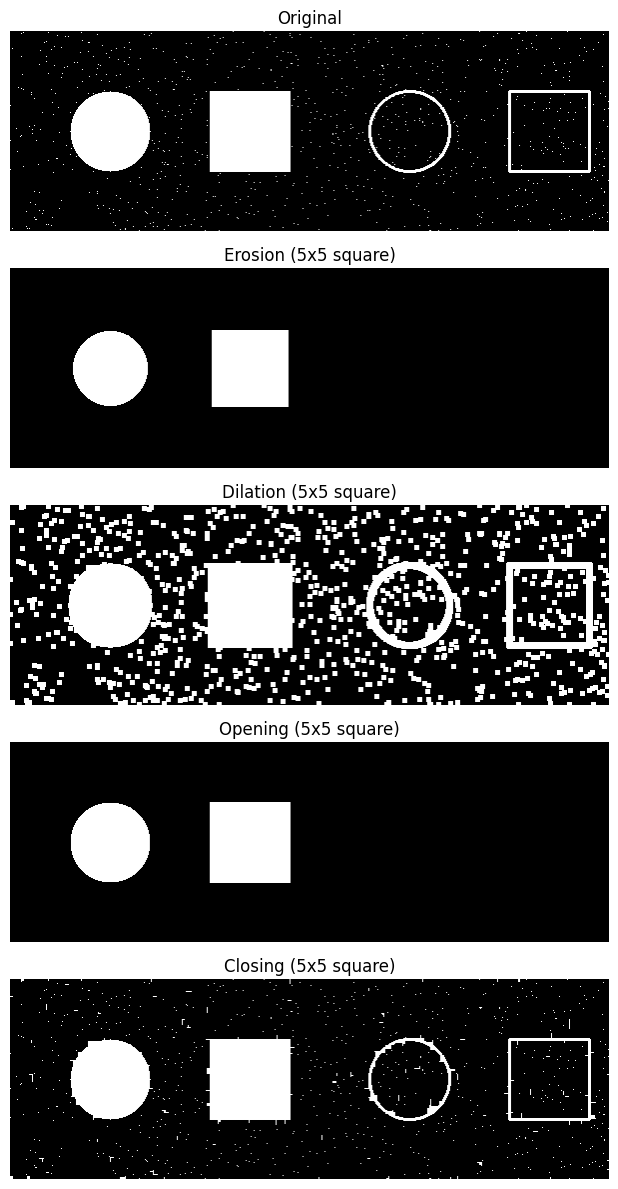

In [4]:
# Apply the four morphological operations with the 5x5 square kernel
erosion  = cv2.erode(image, kernel, iterations=1)
dilation = cv2.dilate(image, kernel, iterations=1)
opening  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

results_square = [
    ('Original', image),
    ('Erosion (5x5 square)', erosion),
    ('Dilation (5x5 square)', dilation),
    ('Opening (5x5 square)', opening),
    ('Closing (5x5 square)', closing),
]

plt.figure(figsize=(14, 12))
for i, (title, img) in enumerate(results_square, 1):
    plt.subplot(5, 1, i)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()


## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

Circular kernel (radius=5, size 11x11):
[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


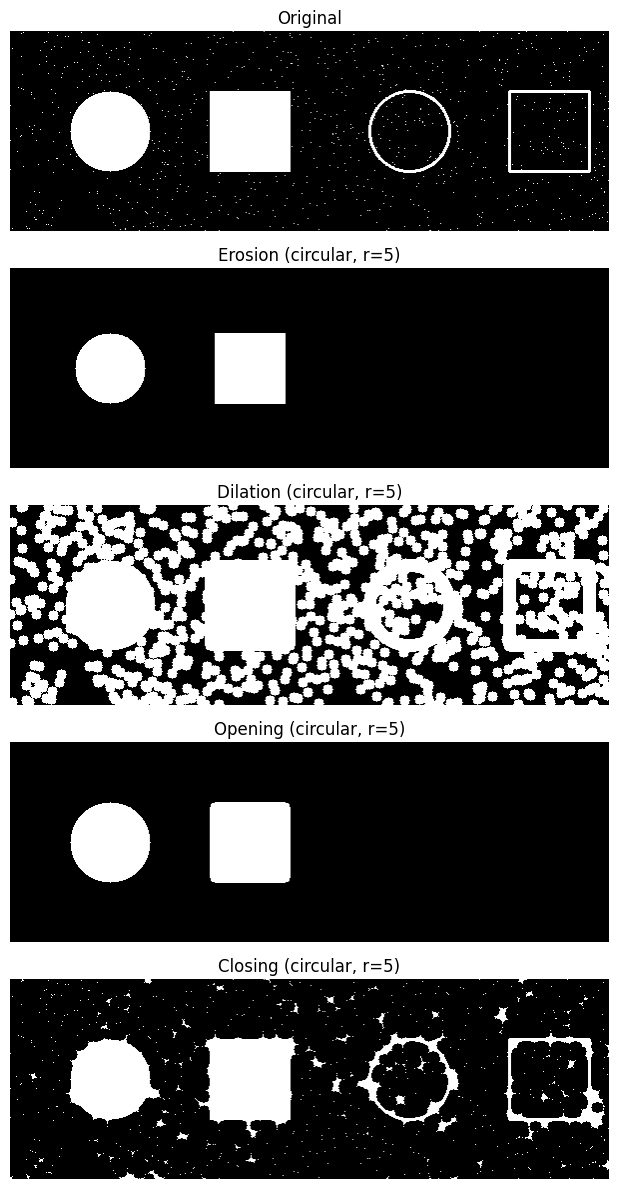

In [6]:
# Apply the four morphological operations with the circular kernel
print("Circular kernel (radius=5, size %dx%d):" % circle_kernel.shape)
print(circle_kernel)

erosion_c  = cv2.erode(image, circle_kernel, iterations=1)
dilation_c = cv2.dilate(image, circle_kernel, iterations=1)
opening_c  = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_c  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

results_circle = [
    ('Original', image),
    ('Erosion (circular, r=5)', erosion_c),
    ('Dilation (circular, r=5)', dilation_c),
    ('Opening (circular, r=5)', opening_c),
    ('Closing (circular, r=5)', closing_c),
]

plt.figure(figsize=(14, 12))
for i, (title, img) in enumerate(results_circle, 1):
    plt.subplot(5, 1, i)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()


## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



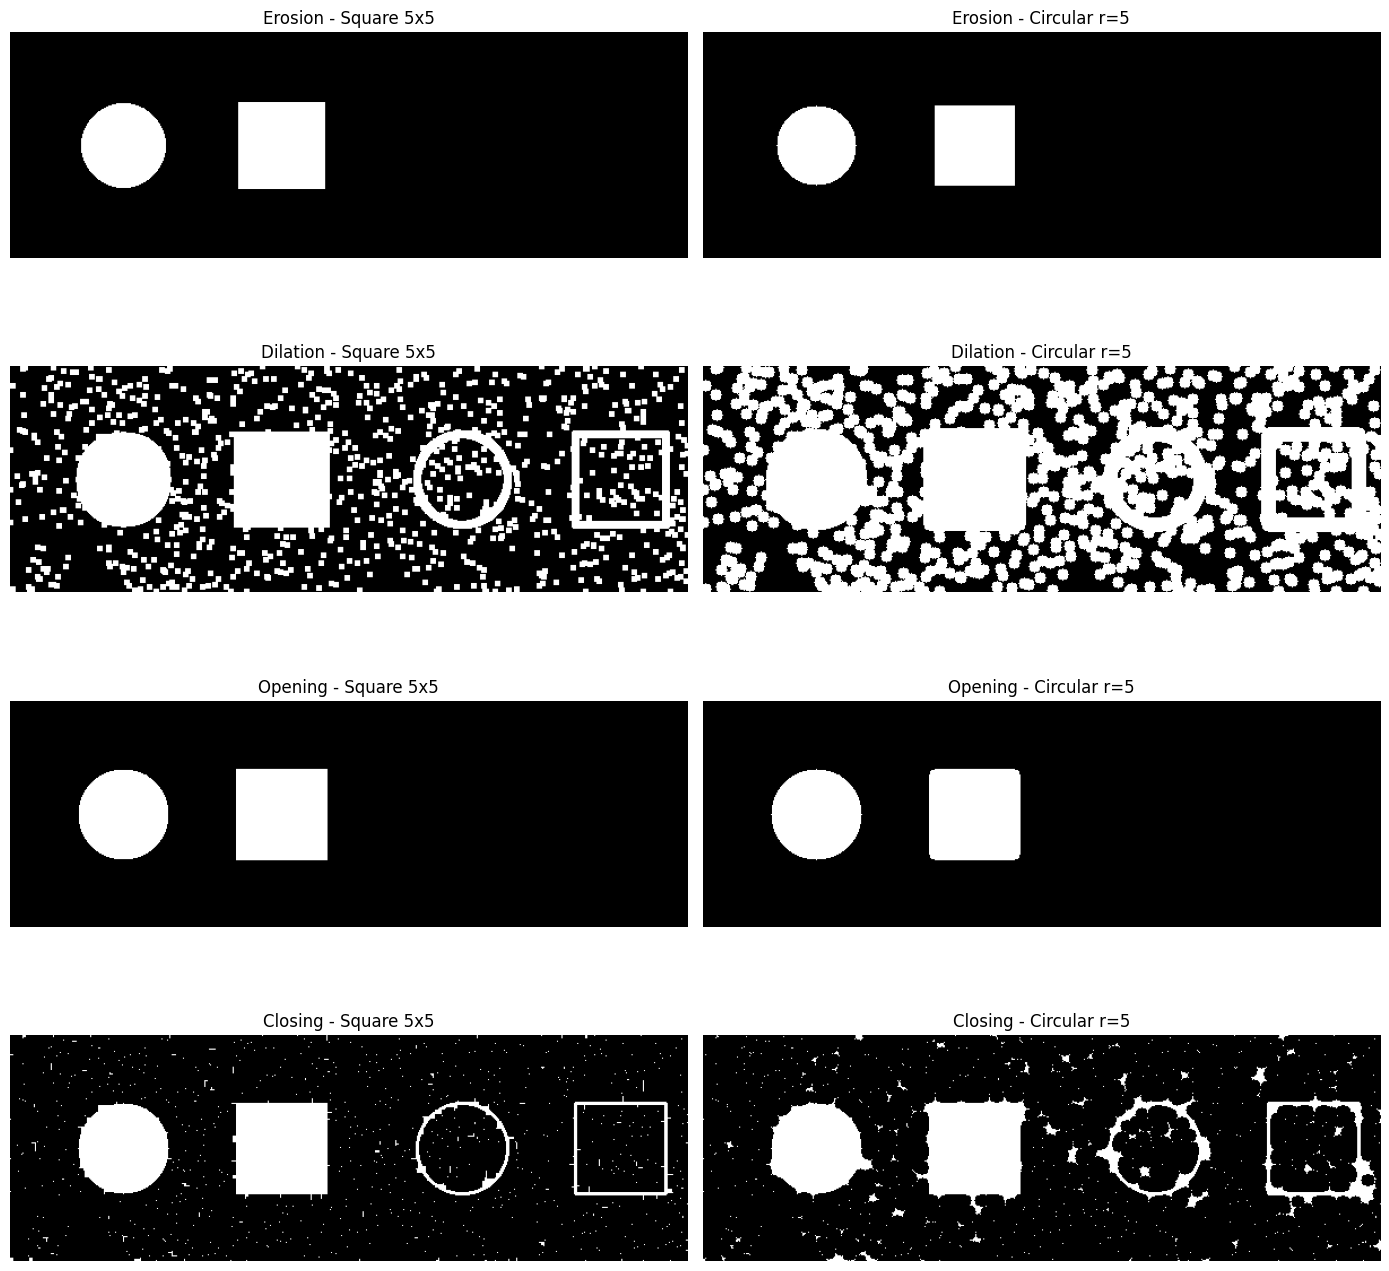

Remaining white pixels (foreground area):
Operation      Square   Circular
Erosion         10335       8903
Dilation        35685      67938
Opening         11583      11547
Closing         14707      17834
Original        14165


In [7]:
# Side-by-side comparison: square vs circular kernel
names = ['Erosion', 'Dilation', 'Opening', 'Closing']
sq = [erosion, dilation, opening, closing]
ci = [erosion_c, dilation_c, opening_c, closing_c]

plt.figure(figsize=(14, 14))
for i, n in enumerate(names):
    plt.subplot(4, 2, 2*i + 1); plt.imshow(sq[i], cmap='gray'); plt.title(n + ' - Square 5x5'); plt.axis('off')
    plt.subplot(4, 2, 2*i + 2); plt.imshow(ci[i], cmap='gray'); plt.title(n + ' - Circular r=5'); plt.axis('off')
plt.tight_layout()
plt.show()

print("Remaining white pixels (foreground area):")
print("%-10s %10s %10s" % ("Operation", "Square", "Circular"))
for n, a, b in zip(names, sq, ci):
    print("%-10s %10d %10d" % (n, np.count_nonzero(a), np.count_nonzero(b)))
print("%-10s %10d" % ("Original", np.count_nonzero(image)))


### Answer — Square vs Circular Kernel

**Shape of the effect.** The structuring element's shape is imprinted on the result. The 5×5 square reaches further along the diagonals than along the horizontal/vertical axes, so it acts in a box-like way. The circular kernel (radius 5, i.e. 11×11) reaches the same distance in every direction (isotropic), and it is also physically larger than the 5×5 square, so its effect is stronger.

**Erosion.** Both kernels remove all the single-pixel salt noise and completely erase the thin (2 px) hollow circle and hollow rectangle, keeping only the solid shapes. The circular kernel shrinks the solid shapes more (8,903 white pixels left vs 10,335 for the square kernel) because it is larger. The solid circle stays round in both cases, and the circular kernel leaves the rectangle with slightly rounded corners.

**Dilation.** Every object grows and the noise pixels become blobs. With the square kernel each noise pixel becomes a small square and the shapes keep sharp corners. With the circular kernel each noise pixel becomes a larger disc, many of them merge together, and the rectangle gets rounded corners. The circular result has far more white (67,938 vs 35,685 pixels). The hollow shapes survive and become thicker with both kernels.

**Opening (erosion → dilation).** Both kernels remove the salt noise and the thin hollow outlines while restoring the solid shapes to roughly their original size. The difference is at the corners: the square kernel gives back the rectangle with perfectly sharp corners, while the circular kernel leaves them slightly rounded, because a circle cannot fit into a sharp 90° corner. The solid circle is preserved well by both.

**Closing (dilation → erosion).** Closing does not remove the noise; it fills gaps and connects nearby pixels. The square kernel produces small angular specks and keeps the shape outlines fairly crisp. The circular kernel is larger, so it merges many more noise pixels into rounded blobs, and it also fills in and bulges the area near the shapes (17,834 vs 14,707 white pixels). The hollow shapes are kept in both, but with the circular kernel their outlines look thicker and blobbier.

**Summary.** A square kernel favours straight edges and sharp right-angle corners, so it suits rectangular objects. A circular kernel works equally in all directions and gives smooth, rounded results, but it rounds off sharp corners and, being larger here, removes or adds more. The kernel's *size* decides how much changes; its *shape* decides how the edges and corners change.


**Name:** Fatimah Saad Alghamdi

**ID:** 2240002658